# 4. Chaotic divergence — a 1e-16 nudge changes everything

**The lie.** *"A tiny error in the initial condition stays tiny."*

For chaotic systems, nearby trajectories separate *exponentially*:
`|Δ(t)| ≈ Δ₀ · e^{λt}`. Precision sets how far you can predict, but it can never
make a chaotic system predictable forever.

## The setup

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

matplotlib.rcParams["figure.dpi"] = 110
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

In [2]:
def logistic(r, x0, n):
    x = np.empty(n)
    x[0] = x0
    for i in range(1, n):
        x[i] = r * x[i - 1] * (1.0 - x[i - 1])
    return x

r = 4.0                     # fully chaotic; Lyapunov exponent = ln 2
n = 60
x0 = 0.3
perturb = 1e-16

## The reality

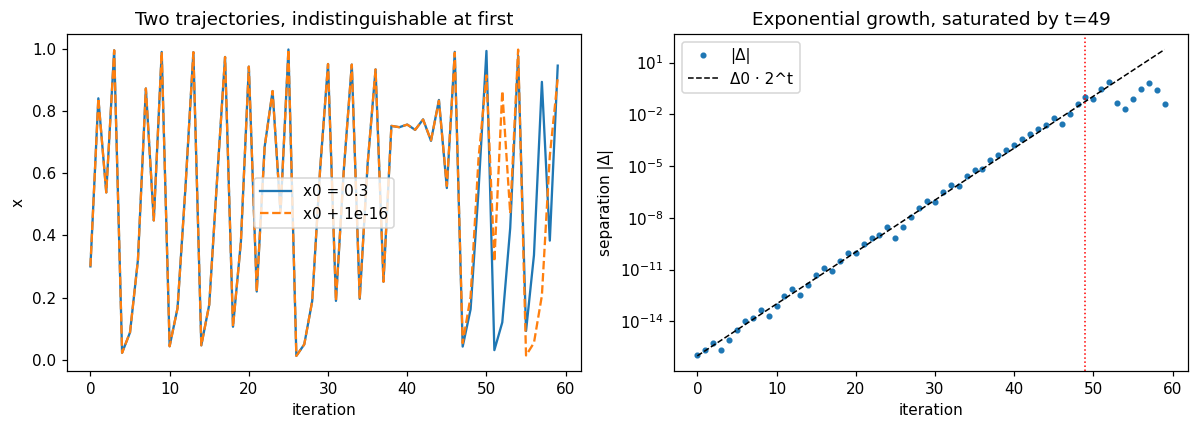

measured Lyapunov exponent = 0.7027   (ln 2 = 0.6931)
halving the initial error buys only 1.0 more iterations of prediction


In [3]:
a = logistic(r, x0, n)
b = logistic(r, x0 + perturb, n)
sep = np.abs(a - b)
first_sat = np.argmax(sep > 1e-1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(a, "-", label="x0 = 0.3")
ax[0].plot(b, "--", label=f"x0 + {perturb:g}")
ax[0].set_xlabel("iteration")
ax[0].set_ylabel("x")
ax[0].set_title("Two trajectories, indistinguishable at first")
ax[0].legend()

ax[1].semilogy(sep, "o", ms=3, label="|Δ|")
tt = np.arange(n)
ax[1].semilogy(tt, perturb * np.exp(np.log(2) * tt), "k--", lw=1, label="Δ0 · 2^t")
ax[1].axvline(first_sat, color="r", ls=":", lw=1)
ax[1].set_xlabel("iteration")
ax[1].set_ylabel("separation |Δ|")
ax[1].set_title(f"Exponential growth, saturated by t={first_sat}")
ax[1].legend()

fig.tight_layout()
fig.savefig(FIG / "04_chaos.png", bbox_inches="tight")
plt.show()

lam = np.polyfit(tt[2:first_sat], np.log(sep[2:first_sat]), 1)[0]
print(f"measured Lyapunov exponent = {lam:.4f}   (ln 2 = {np.log(2):.4f})")
print(f"halving the initial error buys only {np.log(2)/lam:.1f} more iterations of prediction")

## The rule

- Chaotic systems **amplify** initial error; better precision buys only
  `log(Δ_tol/Δ₀) / λ` extra iterations — logarithmically, not linearly.
- Forecast skill has a hard horizon. Ensemble methods track the *distribution*,
  not the exact trajectory.
- Do not use a chaotic benchmark to claim a method is "more accurate"; measure
  statistics (invariant measures, Lyapunov exponents), not pointwise agreement.

## Taking it further

- Lorenz (1963); Strogatz, *Nonlinear Dynamics and Chaos*, ch. 10.
- Lyapunov exponent λ; the logistic map at r=4 has λ = ln 2 exactly.
- Lyapunov time = 1/λ — the natural clock of predictability.